# 1. Análise Exploratória de Dados (EDA) & Pré-processamento Inicial
**Unidade Curricular:** Dados e Aprendizagem Automática (DAA)  
**Objetivo:** Compreender a estrutura do dataset, analisar distribuições das variáveis, identificar valores em falta/constantes e preparar os dados para modelação.

In [ ]:
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Configurações de visualização
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
sns.set_theme(style="whitegrid")

# Caminhos dos ficheiros a partir da pasta 'notebooks/'
DATA_DIR = "../data"
TRAIN_PATH = os.path.join(DATA_DIR, "dataset_train.csv")
TEST_PATH = os.path.join(DATA_DIR, "dataset_test_X.csv")

# 1. Carregar os datasets com skipinitialspace=True para ignorar espaços após vírgulas
train_df = pd.read_csv(TRAIN_PATH, skipinitialspace=True)
test_df = pd.read_csv(TEST_PATH, skipinitialspace=True)

# 2. Limpar espaços extra nos nomes das colunas (trimming)
train_df.columns = train_df.columns.str.strip()
test_df.columns = test_df.columns.str.strip()

print(f"Dimensões do Treino: {train_df.shape}")
print(f"Dimensões do Teste: {test_df.shape}")

# 3. Confirmar a coluna Alvo (Target)
target_col = "AGE_RANGE"
print(f"Coluna Alvo no Treino: '{target_col}'")

Dimensões do Treino: (10962, 238)
Dimensões do Teste: (3655, 237)
Coluna Alvo no Treino: 'AGE_RANGE'


## 1.1 Inspecção Geral e Distribuição do Target (AGE_RANGE)
Análise da distribuição da classe etária alvo para verificar o balanceamento das classes.

--- DISTRIBUIÇÃO DA VARIÁVEL ALVO (AGE_RANGE) ---
           Contagem  Percentagem (%)
AGE_RANGE                           
0               207             1.89
1               172             1.57
2               399             3.64
3               377             3.44
4               449             4.10
5               647             5.90
6               859             7.84
7               862             7.86
8               905             8.26
9              1014             9.25
10             1062             9.69
11             1040             9.49
12             1000             9.12
13              823             7.51
14              650             5.93
15              496             4.52


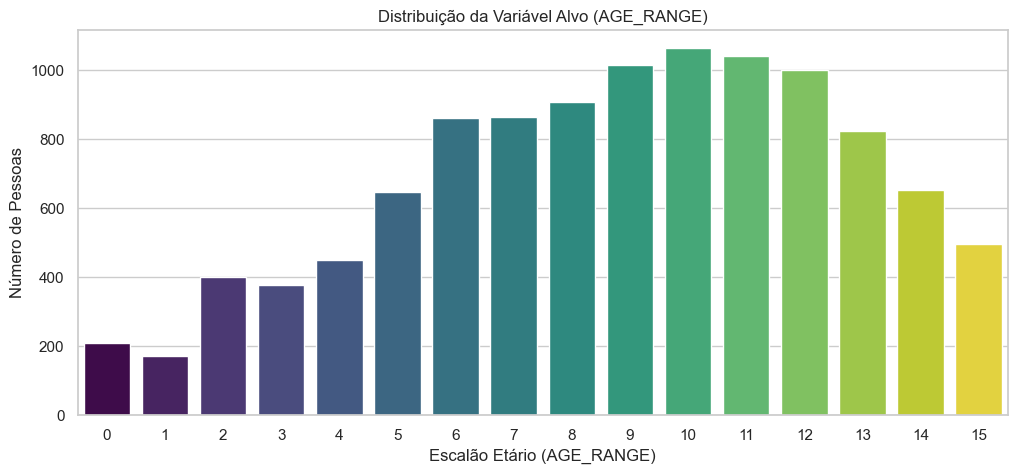

In [10]:
# Contagem e percentagem de cada classe
target_counts = train_df[target_col].value_counts().sort_index()
target_perc = (
    train_df[target_col].value_counts(normalize=True).sort_index() * 100
)

target_summary = pd.DataFrame(
    {"Contagem": target_counts, "Percentagem (%)": target_perc.round(2)}
)
print("--- DISTRIBUIÇÃO DA VARIÁVEL ALVO (AGE_RANGE) ---")
print(target_summary.to_string())

# Gráfico da distribuição do Target (Corrigido para evitar FutureWarning)
plt.figure(figsize=(12, 5))
sns.countplot(
    data=train_df, x=target_col, hue=target_col, palette="viridis", legend=False
)
plt.title("Distribuição da Variável Alvo (AGE_RANGE)")
plt.xlabel("Escalão Etário (AGE_RANGE)")
plt.ylabel("Número de Pessoas")
plt.show()

## 1.2 Resumo Estatístico das Variáveis Numéricas Principais
Cálculo das estatísticas descritivas (Média, Mediana, Desvio Padrão, Intervalo e Amplitude Interquartil - IQR) para as principais variáveis sociodemográficas e de ponderação.

In [11]:
# Seleção de variáveis numéricas sociodemográficas relevantes
id_cols = ["PID", "HHID"]
num_cols = ["WGT", "PROXY", "REFYEAR", "REFMONTH", "HH_ACT", "HH_INACT"]
num_cols = [c for c in num_cols if c in train_df.columns and c not in id_cols]

summary_num = train_df[num_cols].describe().T
summary_num["IQR"] = summary_num["75%"] - summary_num["25%"]

print("--- RESUMO ESTATÍSTICO (VARIÁVEIS NUMÉRICAS) ---")
print(summary_num[["mean", "50%", "std", "min", "max", "IQR"]])

--- RESUMO ESTATÍSTICO (VARIÁVEIS NUMÉRICAS) ---
                 mean       50%         std       min       max      IQR
WGT        614.876103   285.455  804.457773     9.688  7528.206  679.756
PROXY        1.000000     1.000    0.000000     1.000     1.000    0.000
REFYEAR   2019.019796  2019.000    0.139304  2019.000  2020.000    0.000
REFMONTH    10.365171    10.000    1.593975     1.000    12.000    1.000
HH_ACT       0.935048     1.000    0.960860     0.000     6.000    2.000
HH_INACT     0.472177     0.000    0.731180     0.000     5.000    1.000


## 1.3 Identificação de Valores Omissos (NaNs) e Variáveis Constantes
Análise do número de valores em falta no dataset e identificação de colunas sem variância (com valor único) que devem ser removidas.

In [12]:
# 1. Identificar valores em falta
missing_info = train_df.isnull().sum()
missing_info = missing_info[missing_info > 0].sort_values(ascending=False)

print("--- TOP 10 COLUNAS COM MAIS VALORES EM FALTA (NaN) ---")
print(missing_info.head(10))

# 2. Identificar colunas constantes (variância zero)
constant_cols = [col for col in train_df.columns if train_df[col].nunique() <= 1]
print(f"\nColunas constantes identificadas (sem variância): {constant_cols}")

--- TOP 10 COLUNAS COM MAIS VALORES EM FALTA (NaN) ---
IN16    5602
dtype: int64

Colunas constantes identificadas (sem variância): ['PROXY', 'COUNTRY']


## 1.4 Pré-processamento Avançado e Exportação (`train_clean.csv` e `test_clean.csv`)
Processo de tratamento rigoroso dos dados:
1. Remoção de colunas constantes (`PROXY`, `COUNTRY`) e identificadores (`PID`, `HHID`).
2. Tratamento explícito do valor omisso em `IN16` através da criação de um indicador de ausência (`IN16_isna`) e preenchimento com valor distinto (`-1`).
3. Imputação de omissos nas restantes colunas numéricas pela mediana.
4. Codificação robusta de variáveis categóricas (texto) para valores numéricos ordenados.

In [15]:
# 1. Criar cópias para pré-processamento
train_clean = train_df.copy()
test_clean = test_df.copy()

# 2. Remover variáveis constantes e IDs
constant_cols = [col for col in train_clean.columns if train_clean[col].nunique() <= 1]
id_cols = ["PID", "HHID"]
cols_to_drop = list(set(constant_cols + id_cols))

train_clean.drop(columns=cols_to_drop, errors="ignore", inplace=True)
test_clean.drop(columns=cols_to_drop, errors="ignore", inplace=True)

# 3. Tratamento explícito da coluna IN16 (~51% de NaNs)
if "IN16" in train_clean.columns:
    train_clean["IN16_isna"] = train_clean["IN16"].isnull().astype(int)
    test_clean["IN16_isna"] = test_clean["IN16"].isnull().astype(int)
    
    train_clean["IN16"] = train_clean["IN16"].fillna(-1)
    test_clean["IN16"] = test_clean["IN16"].fillna(-1)

# 4. Tratamento de NaNs nas restantes colunas numéricas
# Substituir a imputação pela mediana por um marcador explícito de "Omissão" (-999)
num_cols = train_clean.select_dtypes(include=[np.number]).columns
num_cols = [c for c in num_cols if c != target_col]

for col in num_cols:
    # Opcional: Criar uma flag para colunas com muitos NaNs (ex: > 10%)
    if train_clean[col].isnull().mean() > 0.10:
        train_clean[f"{col}_isna"] = train_clean[col].isnull().astype(int)
        if col in test_clean.columns:
            test_clean[f"{col}_isna"] = test_clean[col].isnull().astype(int)
            
    # Imputar com -999 para que os modelos de árvore isolem este nó
    train_clean[col] = train_clean[col].fillna(-999)
    if col in test_clean.columns:
        test_clean[col] = test_clean[col].fillna(-999)

# 5. Tratamento de colunas categóricas (texto/object)
cat_cols = train_clean.select_dtypes(include=["object"]).columns.tolist()

for col in cat_cols:
    train_clean[col] = train_clean[col].astype(str).str.strip()
    if col in test_clean.columns:
        test_clean[col] = test_clean[col].astype(str).str.strip()
        
    unique_vals = sorted(train_clean[col].unique())
    val_map = {val: idx for idx, val in enumerate(unique_vals)}
    
    train_clean[col] = train_clean[col].map(val_map).fillna(-1)
    if col in test_clean.columns:
        test_clean[col] = test_clean[col].map(val_map).fillna(-1)

# 6. Guardar os datasets processados na pasta 'data/'
train_clean_path = os.path.join(DATA_DIR, "train_clean.csv")
test_clean_path = os.path.join(DATA_DIR, "test_clean.csv")

train_clean.to_csv(train_clean_path, index=False)
test_clean.to_csv(test_clean_path, index=False)

print("--- PRÉ-PROCESSAMENTO AVANÇADO CONCLUÍDO ---")
print(f"Treino limpo: {train_clean_path} | Dimensões: {train_clean.shape}")
print(f"Teste limpo:  {test_clean_path} | Dimensões: {test_clean.shape}")

--- PRÉ-PROCESSAMENTO AVANÇADO CONCLUÍDO ---
Treino limpo: ../data/train_clean.csv | Dimensões: (10962, 235)
Teste limpo:  ../data/test_clean.csv | Dimensões: (3655, 234)
